# NIFTY 50 option sensitivity — end-to-end workflow

This notebook runs the production pipeline in `nifty_sensi` and renders every
figure inline:

1. clean and align the raw option/spot feeds,
2. estimate a put-call-parity risk-free rate per observation date,
3. solve Black-76 implied volatility with explicit solver diagnostics,
4. compute 15 Greeks in documented units,
5. interpolate the IV surface on the fixed moneyness x maturity grid,
6. compare actual Greeks with a synthetic surface and aggregate a portfolio,
7. write a self-contained HTML report with the same figures embedded.

**Setup** — either `pip install -e .` or run from a clone (the next cell adds
`src/` to `sys.path`). Required: `numpy`, `pandas`, `scipy`, `pyarrow`,
`matplotlib`, `IPython`. Interactive widgets are optional (`ipywidgets`).

**Parameters** — edit the next cell directly, or set the environment variables
`NIFTY_SENSI_START`, `NIFTY_SENSI_END` and `NIFTY_SENSI_FORCE` before launch.


In [1]:
import os

# ---------------------------------------------------------------- parameters
START = os.environ.get("NIFTY_SENSI_START") or None  # e.g. "2025-01-01"
END = os.environ.get("NIFTY_SENSI_END") or None      # e.g. "2025-06-30"
FORCE = os.environ.get("NIFTY_SENSI_FORCE", "0") == "1"  # ignore stage caches
REPORT_PATH = "artifacts/report.html"  # relative to the repository root
MAX_DATES = 3      # dates shown in the IV and Greek sections
DPI = 110          # report figure resolution


In [2]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from nifty_sensi.config import load_settings
from nifty_sensi.pipeline.runner import run_pipeline
from nifty_sensi.qc import anomaly_report, dataset_summary
from nifty_sensi.viz import plots_greeks, plots_history, plots_iv, plots_portfolio, plots_qc

plt.rcParams["figure.dpi"] = DPI
plt.rcParams["figure.facecolor"] = "white"


def show(fig):
    # Display once and release, so the inline backend cannot render it again
    # at the end of the cell and later cells cannot flush it.
    display(fig)
    plt.close(fig)


print("repository:", ROOT)


repository: C:\GIT\IE612


## 1. Run the pipeline

Stages are cached by content (`config` + input hashes) and a manifest is written
to `artifacts/runs/<run_id>/manifest.json`. Set `FORCE = True` to recompute.


In [3]:
overrides = {"data": {"start": START, "end": END}, "report": {"dpi": DPI}}
settings = load_settings(overrides=overrides)
result = run_pipeline(settings, force=FORCE)

display(result.summary())
greeks = result.greeks
surfaces = result.surfaces
print(f"run {result.run_id} -> {result.run_dir}")
print(f"{len(greeks):,} contracts | {greeks['date'].nunique()} dates | "
      f"{int(greeks['valid_iv'].sum()):,} usable IVs")


15:42:14 | INFO    | nifty_sensi.runner | prepare: cached (512085 rows)
15:42:15 | INFO    | nifty_sensi.runner | rate: cached (512085 rows)
15:42:15 | INFO    | nifty_sensi.runner | iv: cached (512085 rows)
15:42:15 | INFO    | nifty_sensi.runner | greeks: cached (512085 rows)
15:42:16 | INFO    | nifty_sensi.runner | surface: cached (29280 rows)


,stage,status,rows,seconds
0,prepare,cached,512085,0.0
1,rate,cached,512085,0.0
2,iv,cached,512085,0.0
3,greeks,cached,512085,0.0
4,surface,cached,29280,0.0


run 20261024T101214Z -> C:\GIT\IE612\artifacts\runs\20261024T101214Z
512,085 contracts | 366 dates | 436,792 usable IVs


## 2. Dataset overview and quality checks

`valid_iv` marks rows with a converged solver, a price above intrinsic, an IV
inside the configured bounds and (by default) out-of-the-money moneyness.


In [4]:
summary = pd.DataFrame(
    sorted(dataset_summary(greeks).items()), columns=["metric", "value"]
)
display(summary)
display(anomaly_report(greeks))


,metric,value
0,calls,255002.000000
1,dates,366.000000
2,expiries,94.000000
3,max_days,365.000000
4,median_iv,0.162451
5,median_rate,0.070446
6,puts,257083.000000
7,rate_missing_dates,0.000000
8,rows,512085.000000
9,strikes,179.000000


,check,count
0,contracts over 365 days,0
1,expiry on or before date,0
2,missing rate,0
3,negative or zero price,0
4,duplicate contracts,0
5,IV at solver bounds,66


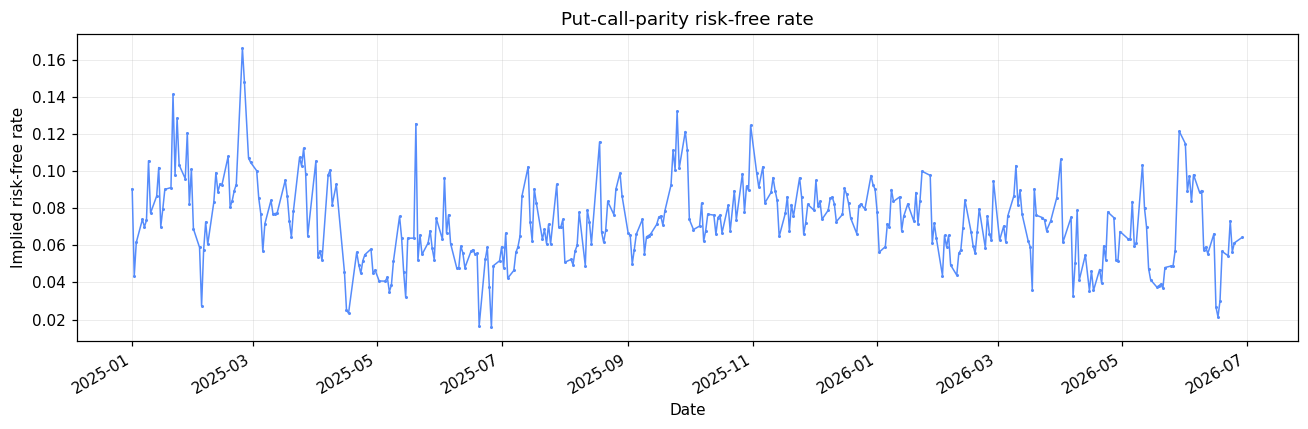

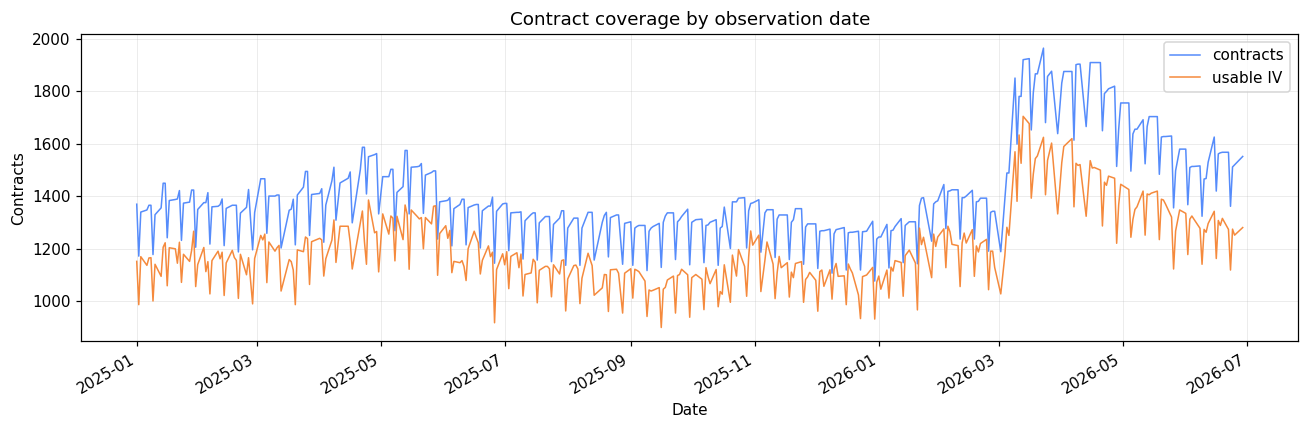

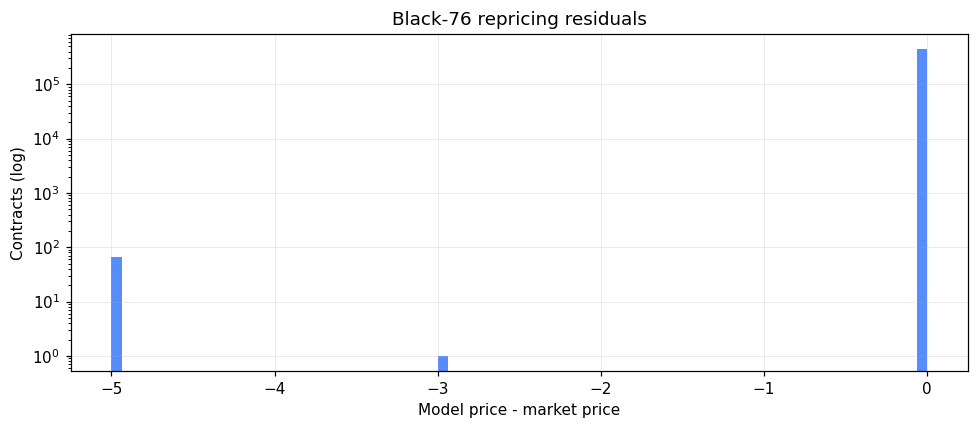

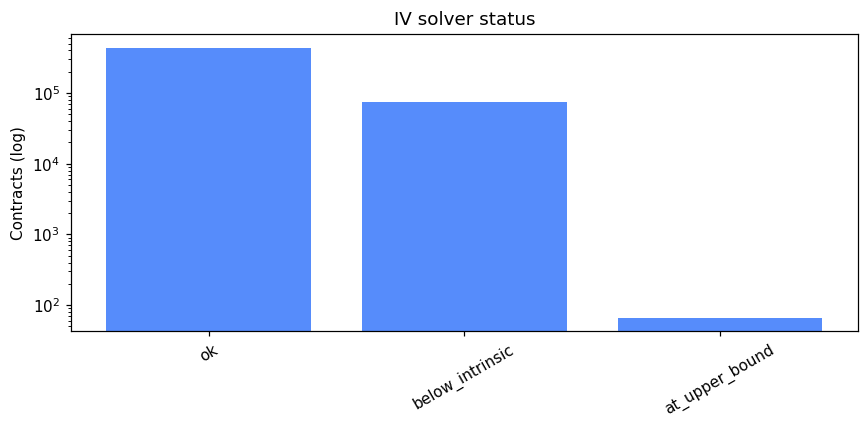

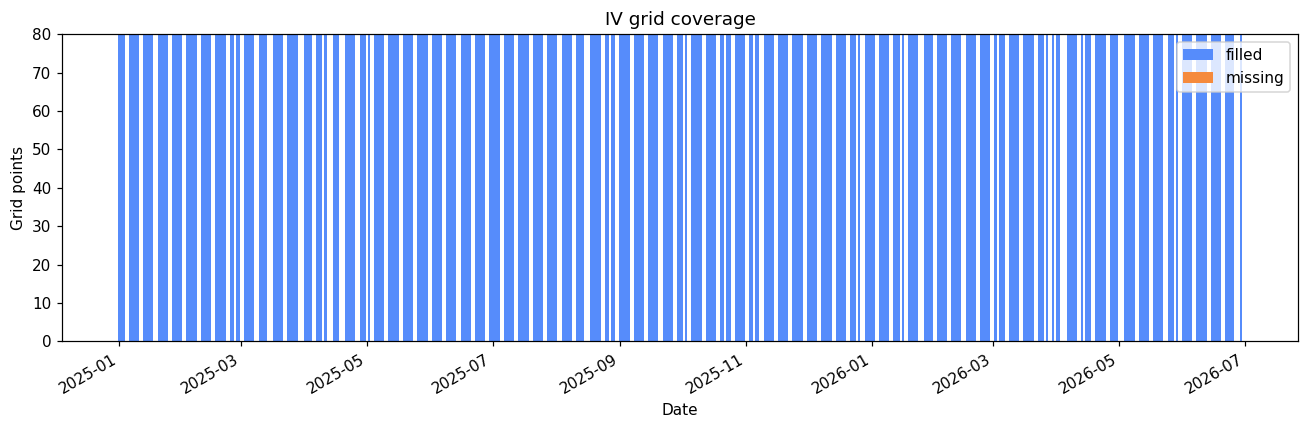

In [5]:
rates_path = settings.interim_dir / "rates.parquet"
rates = pd.read_parquet(rates_path) if rates_path.exists() else pd.DataFrame()
surface_qc_path = settings.processed_dir / "surface_qc.parquet"
surface_qc = pd.read_parquet(surface_qc_path) if surface_qc_path.exists() else pd.DataFrame()

if not rates.empty:
    show(plots_qc.rate_history(rates))
show(plots_qc.coverage_by_date(greeks))
show(plots_qc.repricing_error(greeks))
show(plots_qc.iv_status_breakdown(greeks))
if not surface_qc.empty:
    show(plots_qc.surface_coverage(surface_qc))


## 3. Implied-volatility smile and surface

Smiles are shown for a handful of evenly spaced observation dates; the heatmap
is the processed 10 x 8 grid (moneyness `K/S` x maturity in days).


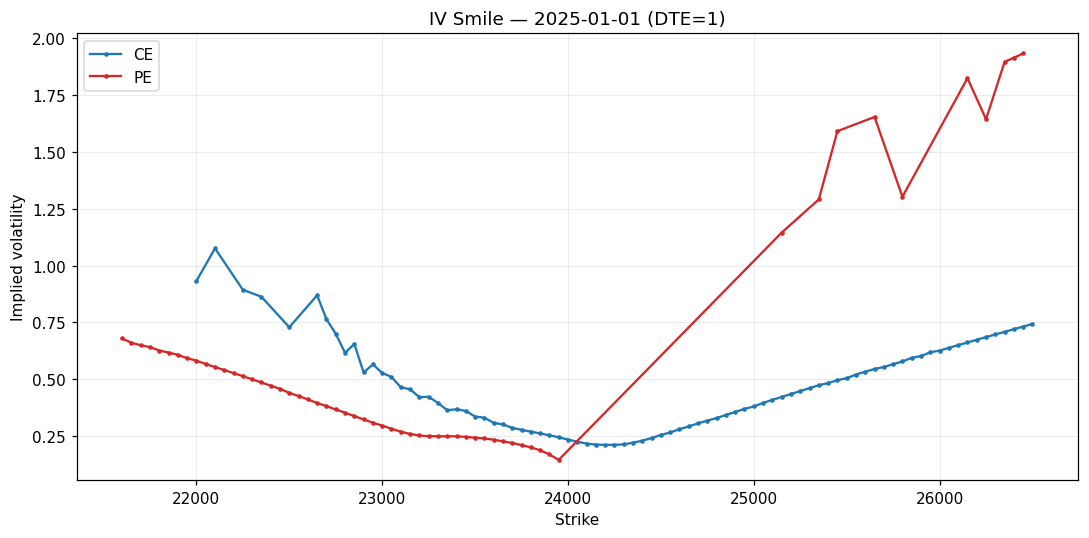

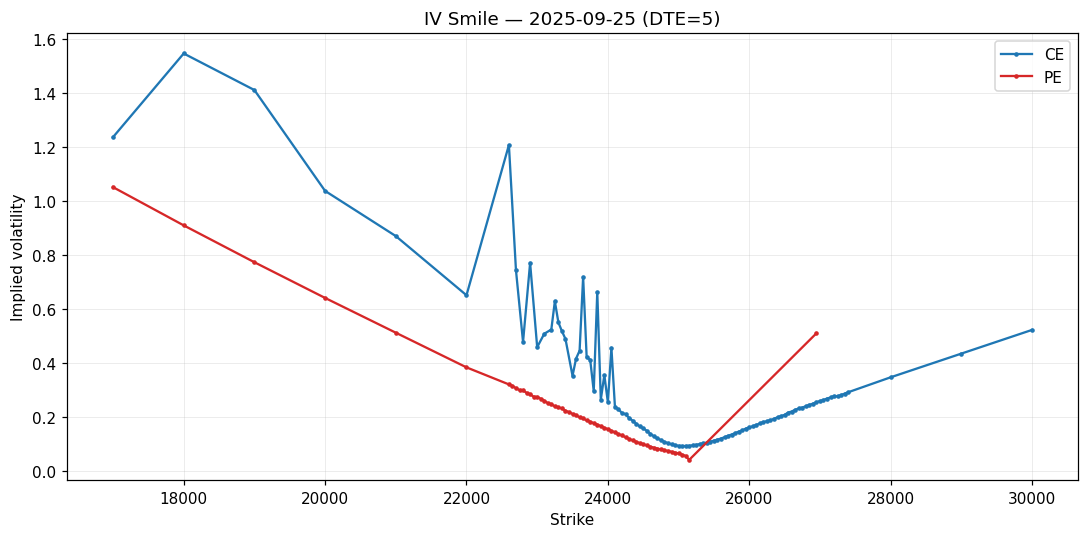

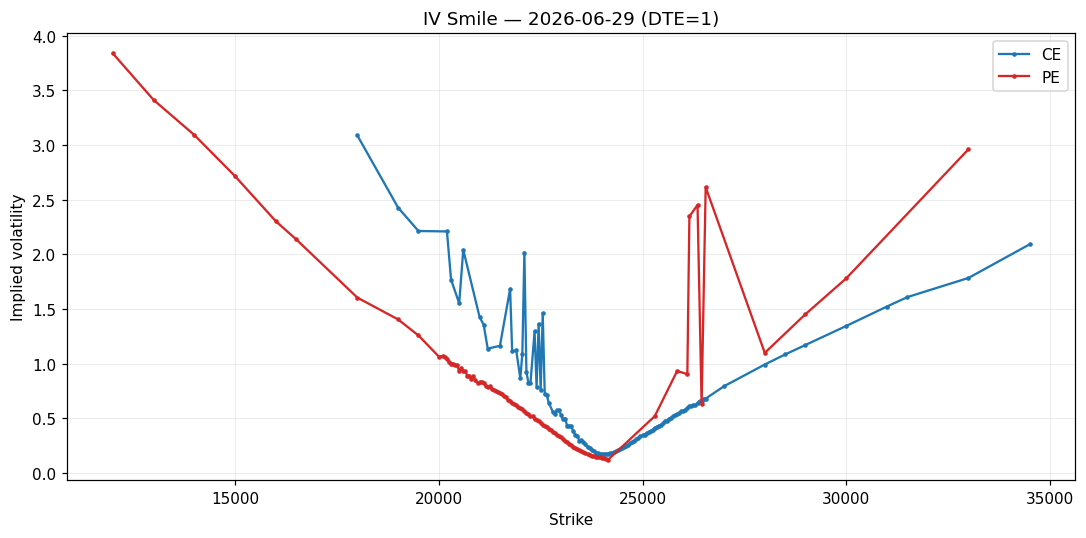

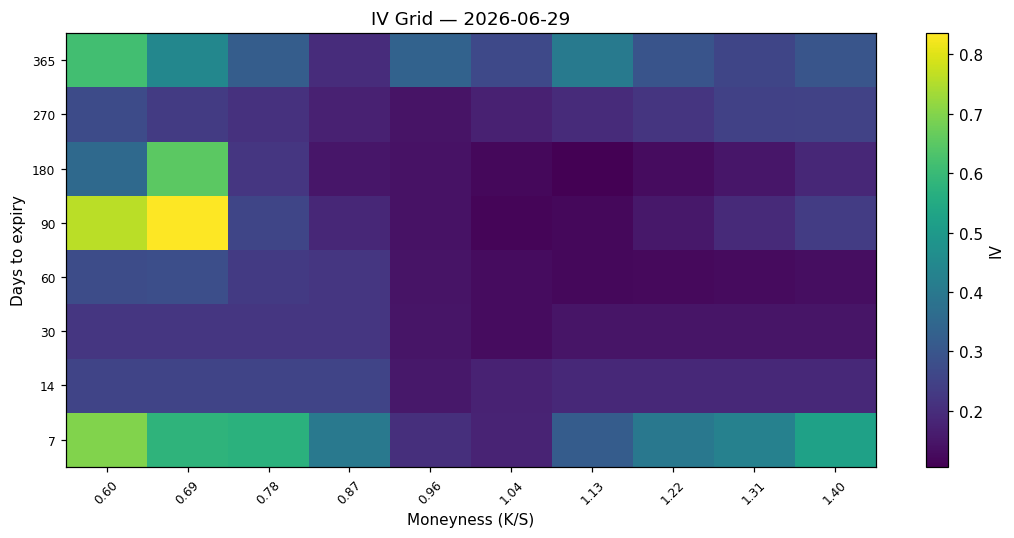

In [6]:
dates = sorted(greeks["date"].unique())
if len(dates) > MAX_DATES:
    picks = np.linspace(0, len(dates) - 1, MAX_DATES).astype(int)
    sample_dates = [dates[i] for i in sorted(set(picks))]
else:
    sample_dates = dates

for date in sample_dates:
    try:
        show(plots_iv.iv_smile(greeks, date))
    except ValueError as exc:
        print(f"{date}: {exc}")

if not surfaces.empty:
    show(plots_iv.surface_heatmap(surfaces, surfaces["date"].max()))


## 4. Greeks

Units: delta per 1.0 spot, gamma per 1.0 spot², vega per volatility point (1%),
theta per calendar day, rho per 1% of rate, vanna per volatility point, vomma per
volatility point², charm/color/veta per calendar day, zomma per volatility point,
ultima per volatility point³.


latest observation date: 2026-06-29


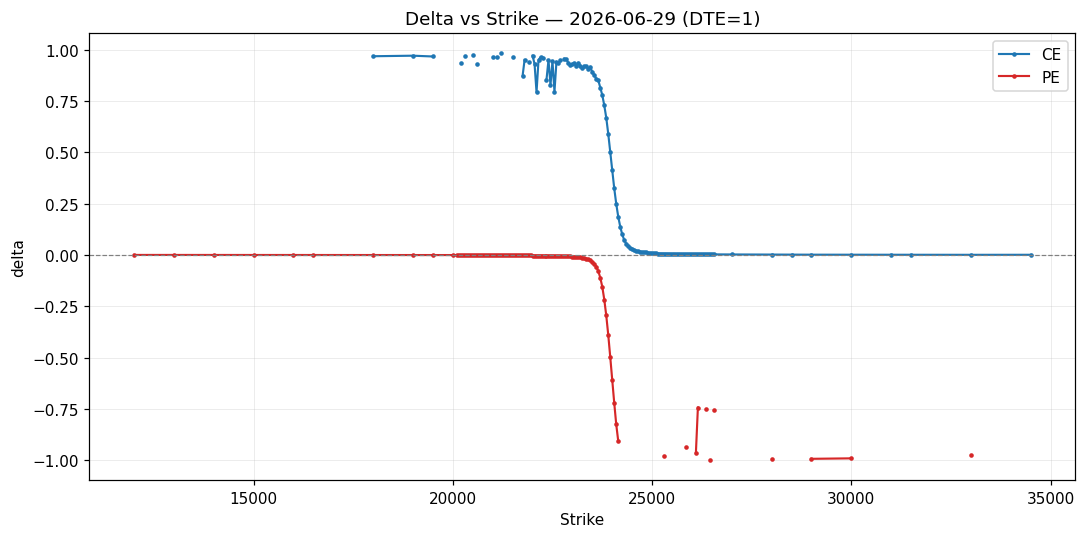

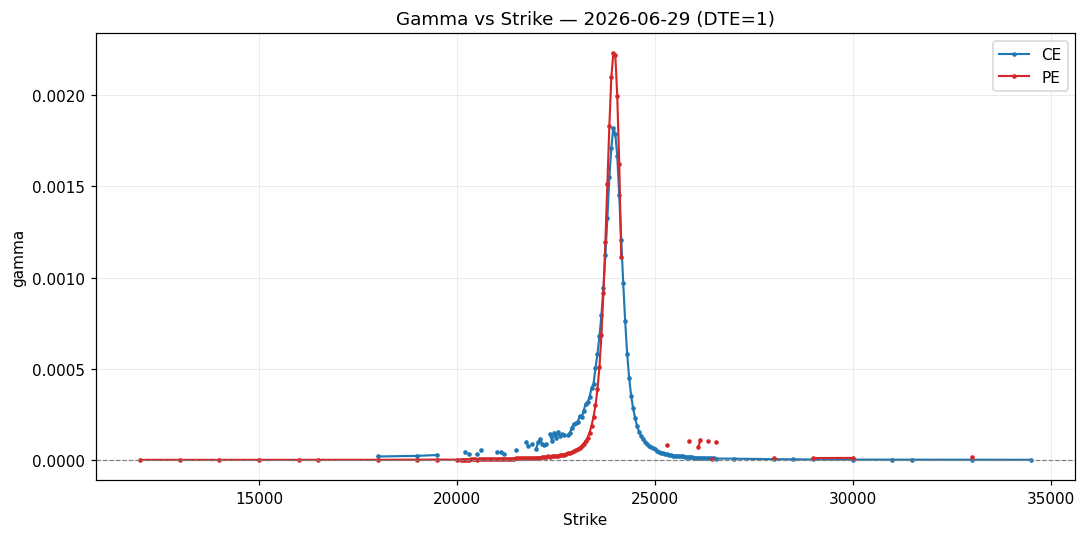

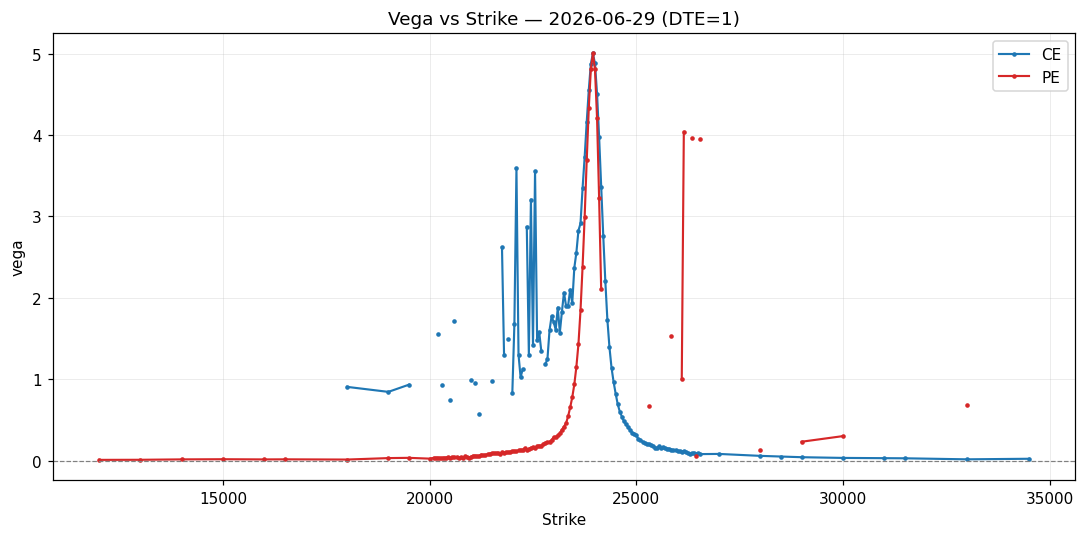

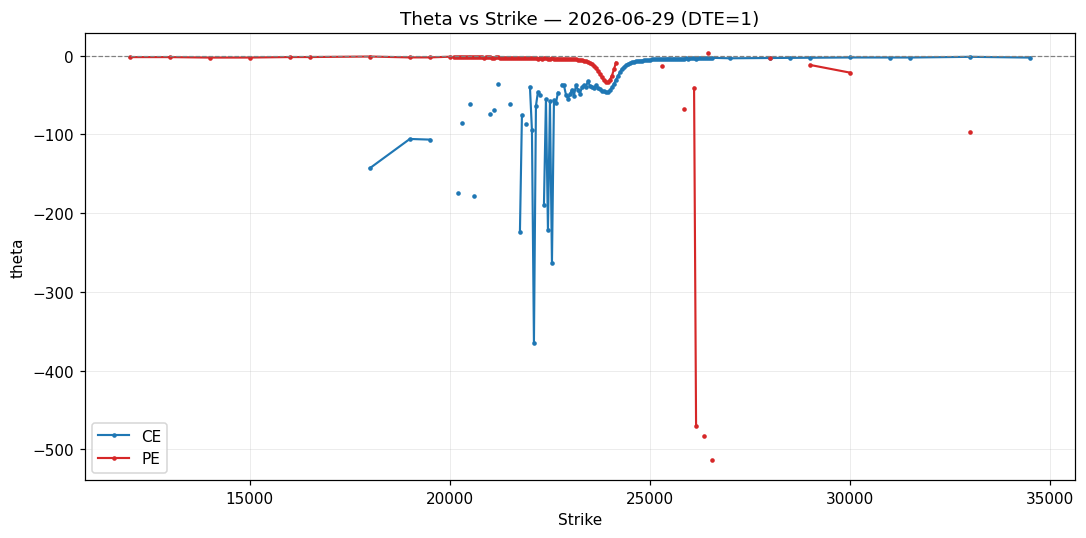

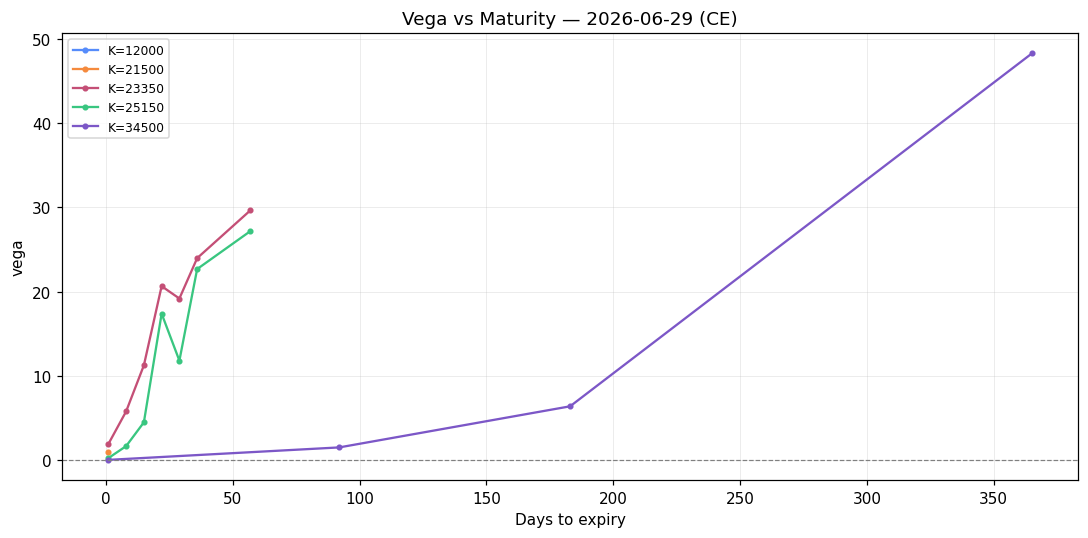

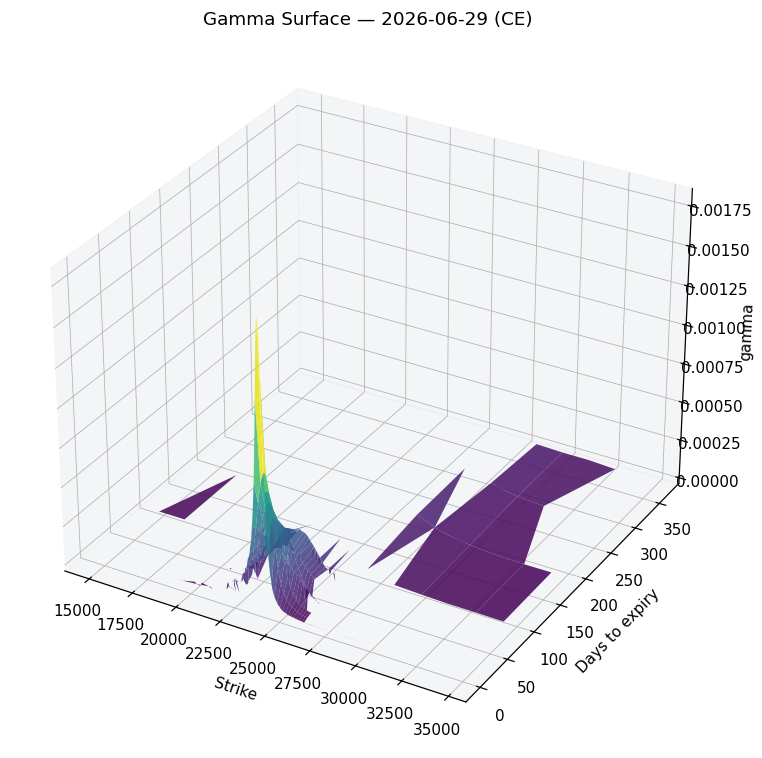

In [7]:
latest = greeks["date"].max()
print("latest observation date:", latest)

for greek in ("delta", "gamma", "vega", "theta"):
    try:
        show(plots_greeks.greek_vs_strike(greeks, latest, greek))
    except ValueError as exc:
        print(f"{greek}: {exc}")

try:
    show(plots_greeks.greek_by_expiry(greeks, latest, "vega"))
except ValueError as exc:
    print("vega by expiry:", exc)

try:
    show(plots_greeks.greek_surface(greeks, latest, "gamma"))
except ValueError as exc:
    print("gamma surface:", exc)


## 5. Actual versus synthetic Greeks

The synthetic surface is rebuilt from observed IVs on a dense strike x maturity
grid (with +/-1% rate scenarios). The comparison below uses the most frequently
observed contract so the history is meaningful.


instrument: CE K=27000 expiry=2026-06-30
observations: 221


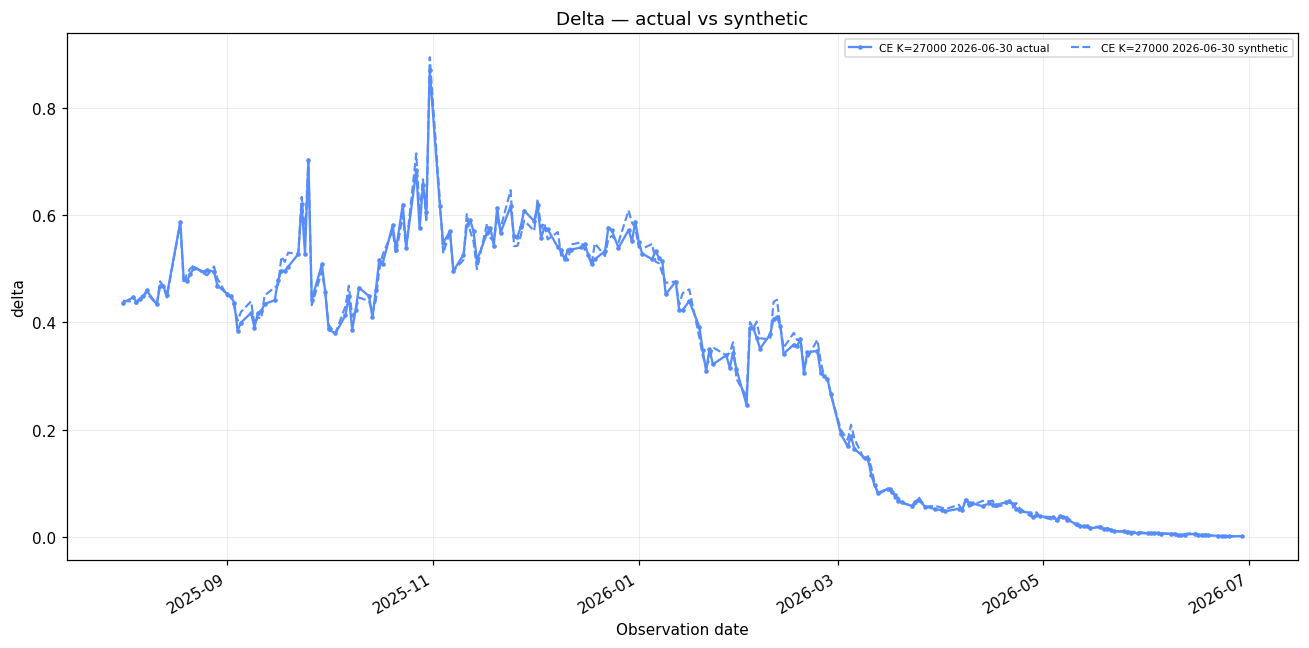

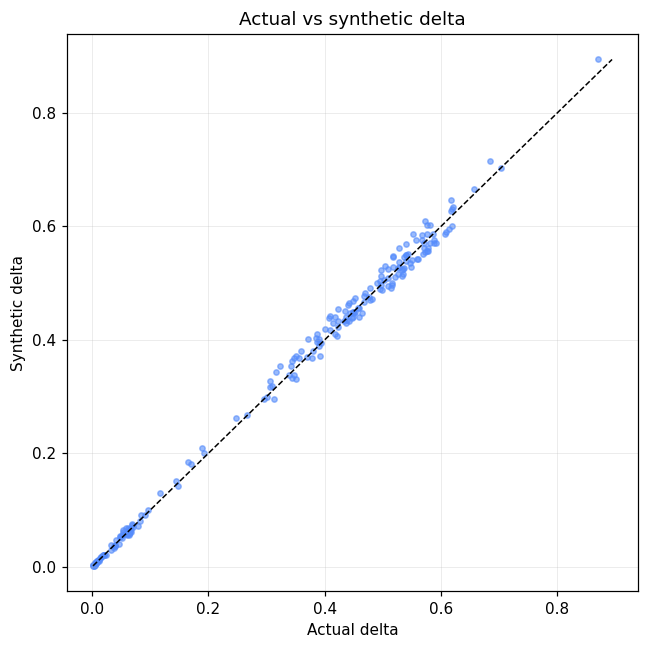

In [8]:
from nifty_sensi.analytics.history import actual_vs_synthetic, prepare_history

history = prepare_history(greeks)
counts = history[history["delta"].notna()].groupby(["_option", "_strike", "_expiry"]).size()
as_of = pd.Timestamp(history["_date"].max())

if len(counts):
    option, strike, expiry = counts.idxmax()
    instrument = (option, float(strike), pd.Timestamp(expiry))
    comparison = actual_vs_synthetic(history, [instrument], "delta", as_of, settings)
    print(f"instrument: {instrument[0]} K={instrument[1]:g} expiry={instrument[2].date()}")
    print(f"observations: {len(comparison)}")
    if not comparison.empty:
        show(plots_history.actual_vs_synthetic(comparison, "delta"))
        show(plots_history.comparison_scatter(comparison, "delta"))
else:
    print("no contract has enough history for a comparison")


## 6. Portfolio aggregation

A long out-of-the-money strangle at the front expiry, sized one lot per leg.
Contributions are signed by direction and multiplied by quantity; portfolio
totals are only shown on dates where every leg has an observation.


spot: 23946.25 | expiry: 2026-07-07
  long CE K=23950
  long PE K=23950


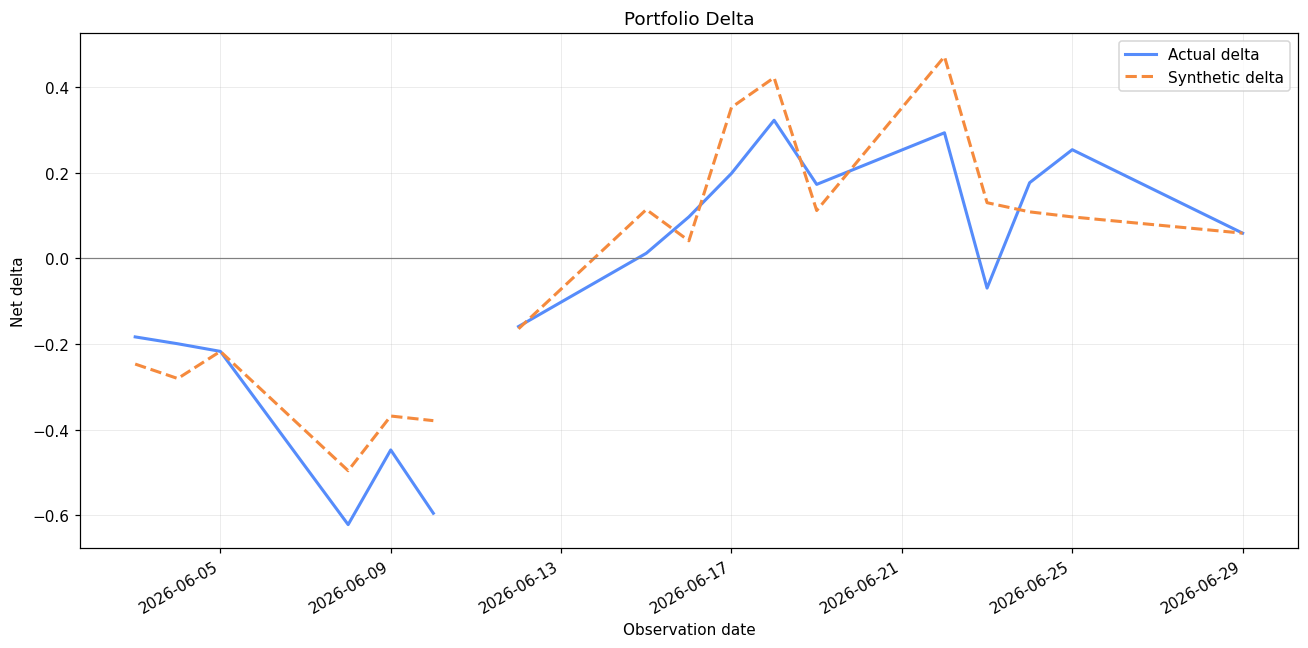

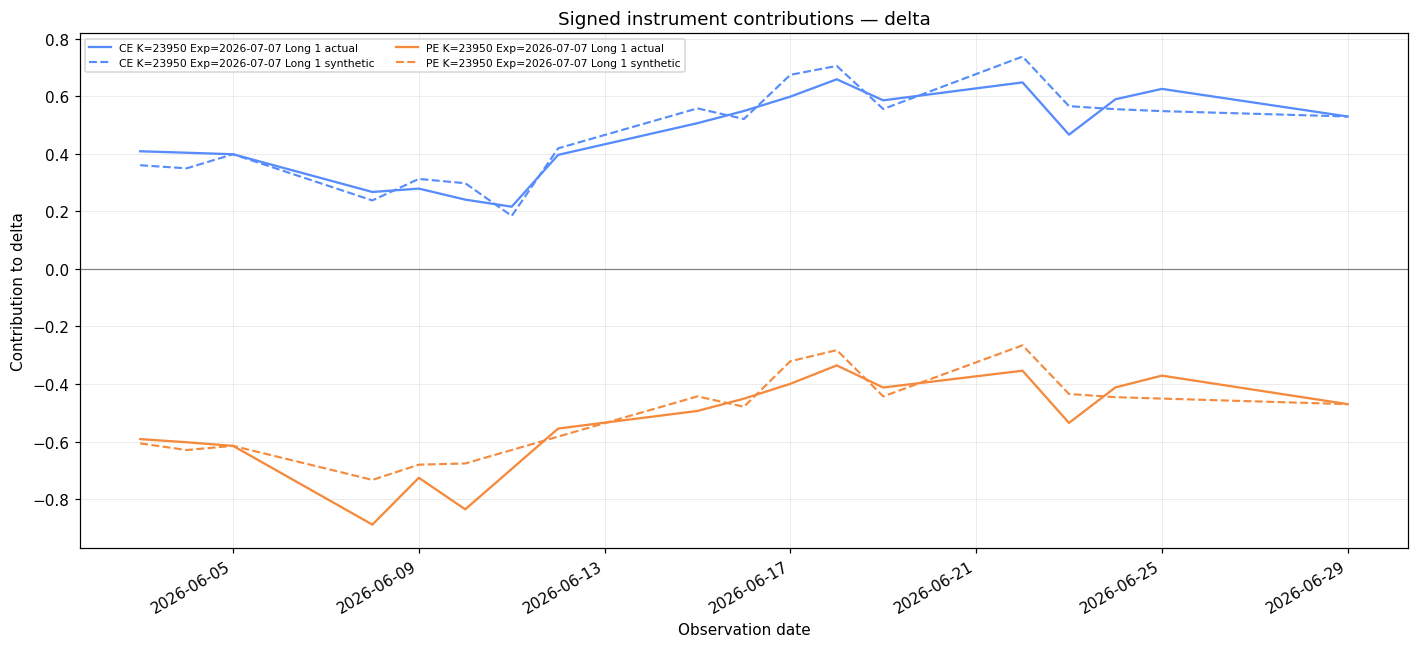

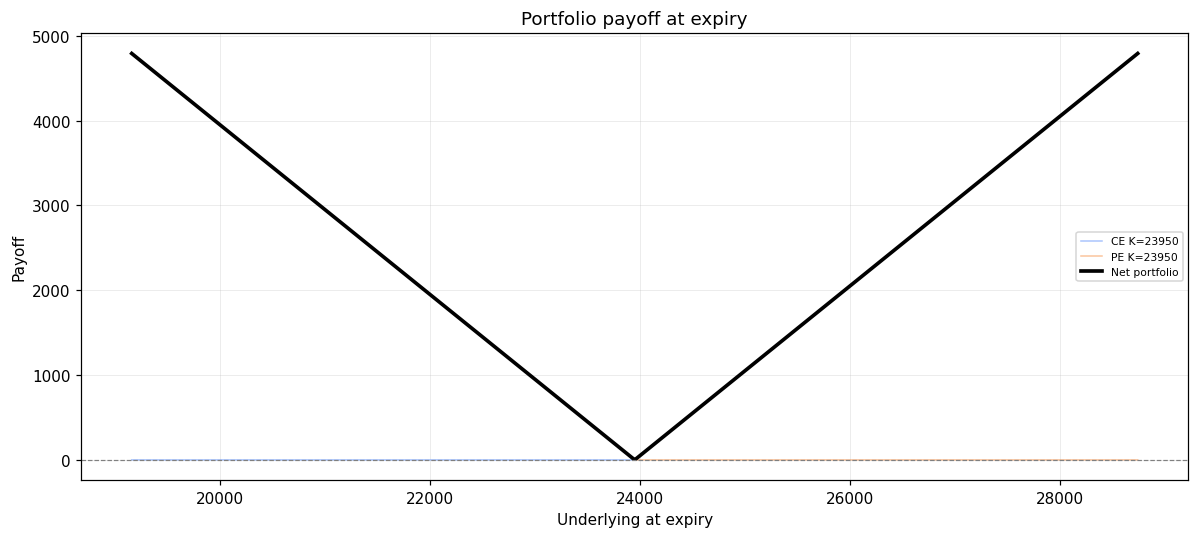

In [9]:
from nifty_sensi.analytics.portfolio import aggregate_portfolio, calculate_contributions, payoff_curve

today = greeks[(greeks["date"] == latest) & greeks["valid_iv"]]
spot = float(today["spot"].median())
front = today[today["days_to_exp"] >= 5]
if front.empty:
    front = today
expiry = sorted(front["expiry"].unique())[0]

legs = []
if not front.empty:
    for option_type in ("CE", "PE"):
        side = front[(front["expiry"] == expiry) & (front["option_type"] == option_type)]
        if side.empty:
            continue
        row = side.loc[(side["strike"] - spot).abs().idxmin()]
        legs.append((option_type, float(row["strike"]), pd.Timestamp(expiry)))

print("spot:", spot, "| expiry:", expiry)
for leg in legs:
    print(f"  long {leg[0]} K={leg[1]:g}")

if legs:
    positions = {leg: {"direction": 1, "quantity": 1} for leg in legs}
    contributions = calculate_contributions(history, positions, "delta", as_of, settings)
    portfolio = aggregate_portfolio(contributions, len(legs))
    if not portfolio.empty:
        show(plots_portfolio.portfolio_totals(portfolio, "delta"))
    show(plots_portfolio.contributions(contributions, "delta"))
    show(plots_portfolio.payoff(payoff_curve(positions)))
else:
    print("no usable legs for a portfolio example")


## 7. Optional interactive exploration

The widgets below are available when `ipywidgets` is installed. When it is not,
the static figures above cover the same views; the notebook always runs.


In [10]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [11]:
from nifty_sensi.viz import interactive_greeks, interactive_history, interactive_portfolio

if interactive_greeks.available():
    display(interactive_greeks.greek_explorer(greeks, settings))
else:
    print("ipywidgets is not installed: pip install ipywidgets")
    print("Falling back to the static figures rendered above.")

if interactive_history.available():
    display(interactive_history.history_explorer(greeks, settings))

if interactive_portfolio.available():
    display(interactive_portfolio.portfolio_builder(greeks, settings))


## 8. Self-contained HTML report

The report embeds every figure as base64 PNG, so it is portable: no external
assets, no server, no JavaScript. It is written to `artifacts/report.html`.


In [14]:
from nifty_sensi.reporting import build_run_report

report_file = build_run_report(
    settings, run_id=result.run_id, output=settings.root / REPORT_PATH
)
report_html = Path(report_file).read_text(encoding="utf-8")
print("figures embedded:", report_html.count("<figure>"))
print("size:", round(len(report_html) / 1024), "KB")
print("open:", report_file)


Report written to C:\GIT\IE612\artifacts\report.html (18 figures)
figures embedded: 18
size: 1394 KB
open: C:\GIT\IE612\artifacts\report.html


### Where things are written

| Path | Contents |
| --- | --- |
| `data/interim/prepared.parquet` | cleaned and aligned option rows |
| `data/interim/rates.parquet` | parity rate per observation date + source |
| `data/interim/iv.parquet` | IV, solver status, repricing error, OTM flag |
| `data/processed/greeks.parquet` | all 15 Greeks for usable contracts |
| `data/processed/surfaces.parquet` | 10 x 8 IV grid per date |
| `artifacts/runs/<run_id>/` | manifest, run log and HTML report |
| `artifacts/report.html` | latest portable report |

**Notes on correctness**

* Prices are discounted Black-76 on `F = S exp(rT)`; NIFTY is treated as a price
  index (no dividend yield).
* The risk-free rate comes from put-call parity (median across matched pairs) with
  a rolling-median then constant fallback; the source is recorded per date.
* Deep in-the-money quotes can trade below discounted intrinsic (stale prints);
  they are flagged `below_intrinsic`, excluded from `valid_iv` and never used in
  the surface.
* The calendar-spread diagnostic counts negative moves in total variance
  `w = IV² T`; violations are reported rather than silently smoothed.
